# Reto 2 — clasificación landuse (continuación del reto 1)

Segunda parte de la comparación. El reto 1 trabajó con 3 escenas y 9 modelos;
aquí se cambia el dataset (cobertura terrestre: `denseresidential`, `harbor` y
`river`) y se reduce la comparación a **cuatro modelos**, elegidos a partir de
lo que el reto 1 ya había demostrado. El objetivo no es repetir nueve
entrenamientos, sino comprobar si las conclusiones del reto 1 se mantienen en
otro problema.

| Grupo | Modelo | Cuaderno | Resultados |
|---|---|---|---|
| CNN | CNN base (8-16-32, `Rescaling(1/255)` interno) | `LandUseCNN.ipynb` | `resultados/cnn/base/` |
| CNN | CNN mejorada con la receta v2 del reto 1 | `LandUseCNN.ipynb` | `resultados/cnn/mejorada/` |
| DL no secuencial | DenseNet121 preentrenada en ImageNet + fine-tuning | `LandUseDenseNet.ipynb` | `resultados/densenet/` |
| IA generativa | ViT-B/16 preentrenado en ImageNet + fine-tuning | `LandUseViT.ipynb` | `resultados/vit/` |

Los cuatro modelos usan el mismo split y las mismas métricas. La comparación
completa, las **cuatro figuras** y las conclusiones se generan desde
`resultados/`.


## Continuidad con el reto 1

El reto 1 comparó 9 modelos sobre 958 imágenes de 3 escenas. Estos fueron los
resultados finales que justifican las decisiones de esta entrega:

| Modelo del reto 1 | Accuracy | McNemar relevante |
|---|---:|---|
| CNN base | 90,42 % | vs DenseNet121: p = 0,0001 |
| CNN mejorada v1 | 87,08 % | vs CNN base: p = 0,2005 |
| CNN mejorada v2 | 89,17 % | vs CNN base: p = 0,7011; vs v1: p = 0,2668 |
| DenseNet121 | 98,33 % | — |
| ViT desde cero | 88,75 % | vs CNN v2: p = 1,0000; vs DenseNet121: p = 0,0000 |
| ViT preentrenado | 97,50 % | vs ViT desde cero: p = 0,0001; vs DenseNet121: p = 0,6875 |
| Mejor ML (SVM) | 95,42 % | vs DenseNet121: p = 0,0654 |

**Por qué se usan cuatro modelos.** Las tres CNN desde cero son
estadísticamente indistinguibles entre sí (p = 0,2005, 0,2668 y 0,7011), así que
conservar v1 y v2 no añade información. El ViT desde cero empata con la mejor
CNN desde cero (p = 1,0000): sin preentrenamiento, atención y convolución no se
separan. El mejor modelo clásico (SVM, 95,42 %) queda por debajo de DenseNet121
y no aporta una comparación nueva. Por eso el reto 2 conserva un representante
por celda útil: CNN base, CNN mejorada, DenseNet121 y ViT preentrenado.

**Por qué se parte del ViT preentrenado.** En el reto 1 el ViT desde cero fue el
modelo más caro y más difícil: 88,75 %, 2.345 s y 51 épocas, sin superar a la CNN
mejorada v2 (p = 1,0000). El mismo ViT con preentrenamiento subió al 97,50 %
(+8,75 puntos, p = 0,0001) y empató con DenseNet121 (p = 0,6875). Repetir el ViT
desde cero en el reto 2 solo confirmaría lo ya sabido y añadiría coste. El reto 2
arranca del preentrenado y se concentra en la pregunta que sigue abierta: si el
empate atención/convolución se mantiene en un dataset distinto.


## Dataset

- **1.500 imágenes PNG** del dataset local `landuse-dataset/`, 500 por clase:
  `denseresidential`, `harbor` y `river`. El dataset está equilibrado.
- Las imágenes originales son de 256×256. Las CNN y DenseNet trabajan a
  **128×128**; el ViT usa **224×224**, la resolución de su preentrenamiento.
- Split estratificado común: **75 % train, 15 % validación y 25 % test**,
  semilla 20 (`resultados/split.json`). El test tiene 375 imágenes y no se usa
  para entrenar ni para early stopping.


## Protocolo

- Métricas: accuracy, precisión/recall/F1 macro y weighted, Cohen's kappa,
  ROC-AUC one-vs-rest, matriz de confusión, IC 95 % por bootstrap (2.000
  remuestreos) y test exacto de McNemar.
- Cada modelo guarda `metrics.json`, `predictions.csv`,
  `classification_report.txt`, `history.csv` y sus pesos. El ViT guarda
  `model.weights.h5` (~345 MB), ignorado por git; en un clon nuevo se reentrena.
- Los modelos ya entrenados se cargan desde `resultados/` por defecto. Para
  reentrenar, cambia `FORCE_RETRAIN = True` en el cuaderno del modelo.
- `reto-2.ipynb` genera exactamente **cuatro figuras**: barras con IC 95 %,
  matrices de confusión, curvas de aprendizaje y heatmap de F1 por clase.


## Carga de resultados y tabla resumen


In [8]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import f1_score

import common_landuse as cl

sns.set_theme(style="whitegrid", context="notebook")
comparison_dir = cl.result_dir("comparacion")
comparison_dir.mkdir(parents=True, exist_ok=True)

order = ["cnn/base", "cnn/mejorada", "densenet", "vit"]
results = cl.load_all_results()
split_meta = cl.load_split()
predictions = {}

missing = set(order) if results.empty else set(order) - set(results["folder"])
if missing:
    HAS_RESULTS = False
    if results.empty:
        detail = "todavía no hay resultados en resultados/"
    else:
        detail = "faltan resultados de: " + ", ".join(sorted(missing))
    print(
        f"[aviso] {detail}. Ejecuta antes LandUseCNN.ipynb, "
        "LandUseDenseNet.ipynb y LandUseViT.ipynb (o usa nbconvert como indica "
        "el README). Este cuaderno termina aquí sin error: las celdas "
        "siguientes solo se omiten."
    )
else:
    HAS_RESULTS = True
    results = results[results["folder"].isin(order)].copy()
    results["order"] = results["folder"].map(
        {folder: index for index, folder in enumerate(order)}
    )
    results = results.sort_values("order").drop(columns="order").reset_index(drop=True)

    def bootstrap_f1_ci(y_true, y_pred, n_boot=2000, seed=cl.SEED):
        rng = np.random.default_rng(seed)
        scores = []
        for _ in range(n_boot):
            indices = rng.integers(0, len(y_true), len(y_true))
            scores.append(f1_score(y_true[indices], y_pred[indices], average="macro"))
        return np.percentile(scores, [2.5, 97.5])

    interval_rows = []
    for _, row in results.iterrows():
        frame = cl.load_predictions(row["folder"])
        predictions[row["model"]] = frame
        if frame is None:
            accuracy_low = accuracy_high = np.nan
            f1_low = f1_high = np.nan
        else:
            accuracy_low, accuracy_high = cl.bootstrap_accuracy_ci(
                frame["true_class"], frame["predicted_class"]
            )
            f1_low, f1_high = bootstrap_f1_ci(
                frame["true_class"], frame["predicted_class"]
            )
        interval_rows.append(
            {
                "model": row["model"],
                "accuracy_low": accuracy_low,
                "accuracy_high": accuracy_high,
                "f1_low": f1_low,
                "f1_high": f1_high,
            }
        )
    results = results.merge(pd.DataFrame(interval_rows), on="model")

    summary_columns = [
        "model",
        "family",
        "accuracy",
        "f1_macro",
        "f1_weighted",
        "precision_macro",
        "recall_macro",
        "cohen_kappa",
        "roc_auc_ovr_macro",
        "parameters",
        "training_seconds",
        "inference_ms_per_image",
        "epochs",
    ]
    summary = results[summary_columns].copy()
    summary.to_csv(comparison_dir / "model_summary.csv", index=False)

    display_summary = summary.rename(
        columns={
            "model": "Modelo",
            "family": "Familia",
            "accuracy": "Accuracy",
            "f1_macro": "F1 macro",
            "f1_weighted": "F1 weighted",
            "precision_macro": "Precisión macro",
            "recall_macro": "Recall macro",
            "cohen_kappa": "Kappa",
            "roc_auc_ovr_macro": "AUC OVR",
            "parameters": "Parámetros",
            "training_seconds": "Entrenamiento (s)",
            "inference_ms_per_image": "Inferencia (ms/img)",
            "epochs": "Épocas",
        }
    )
    display_summary["Familia"] = display_summary["Familia"].replace(
        {
            "DL (non-sequential)": "DL (no secuencial)",
            "IA generativa (Transformer)": "IA generativa",
        }
    )
    display_summary["Parámetros"] = display_summary["Parámetros"].map(
        lambda value: f"{int(value):,}"
    )
    display_summary["Entrenamiento (s)"] = display_summary["Entrenamiento (s)"].map(
        lambda value: f"{value:,.0f}"
    )
    display_summary["Inferencia (ms/img)"] = display_summary["Inferencia (ms/img)"].map(
        lambda value: f"{value:.1f}"
    )
    display_summary.round(4)


## Figura 1: accuracy y F1 macro con IC 95 %


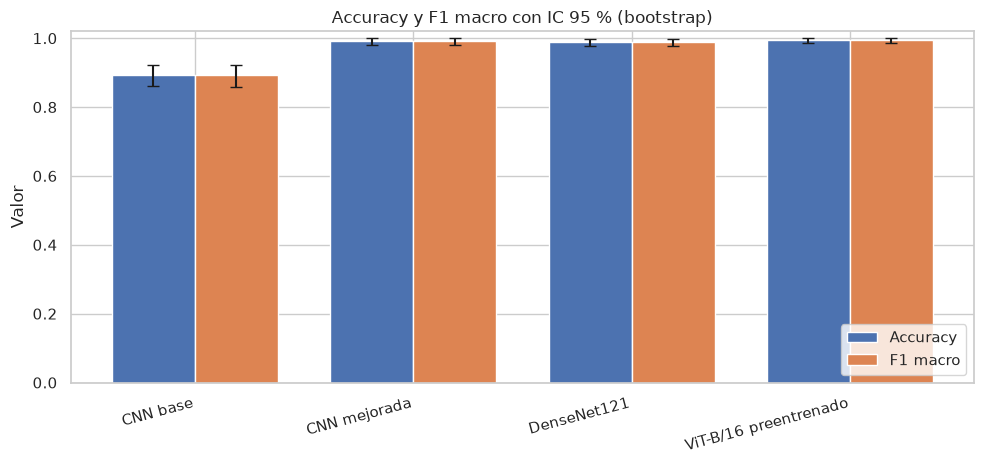

In [2]:
if not HAS_RESULTS:
    print("[aviso] Sin resultados entrenados: figura omitida.")
else:
    fig, ax = plt.subplots(figsize=(10, 4.8))
    positions = np.arange(len(results))
    width = 0.38
    ax.bar(
        positions - width / 2,
        results["accuracy"],
        width,
        yerr=[
            results["accuracy"] - results["accuracy_low"],
            results["accuracy_high"] - results["accuracy"],
        ],
        capsize=4,
        label="Accuracy",
    )
    ax.bar(
        positions + width / 2,
        results["f1_macro"],
        width,
        yerr=[
            results["f1_macro"] - results["f1_low"],
            results["f1_high"] - results["f1_macro"],
        ],
        capsize=4,
        label="F1 macro",
    )
    ax.set_xticks(positions, results["model"], rotation=15, ha="right")
    ax.set_ylim(0, 1.02)
    ax.set_ylabel("Valor")
    ax.set_title("Accuracy y F1 macro con IC 95 % (bootstrap)")
    ax.legend(loc="lower right")
    fig.tight_layout()
    fig.savefig(comparison_dir / "barras_accuracy_f1.png", dpi=150, bbox_inches="tight")
    plt.show()


**Qué mirar.** Si los intervalos de los dos modelos preentrenados se
solapan, la diferencia de accuracy no basta para ordenarlos. Los intervalos
también muestran cuánto aprieta el test de 375 imágenes: cada acierto vale
0,27 puntos.


## Figura 2: matrices de confusión


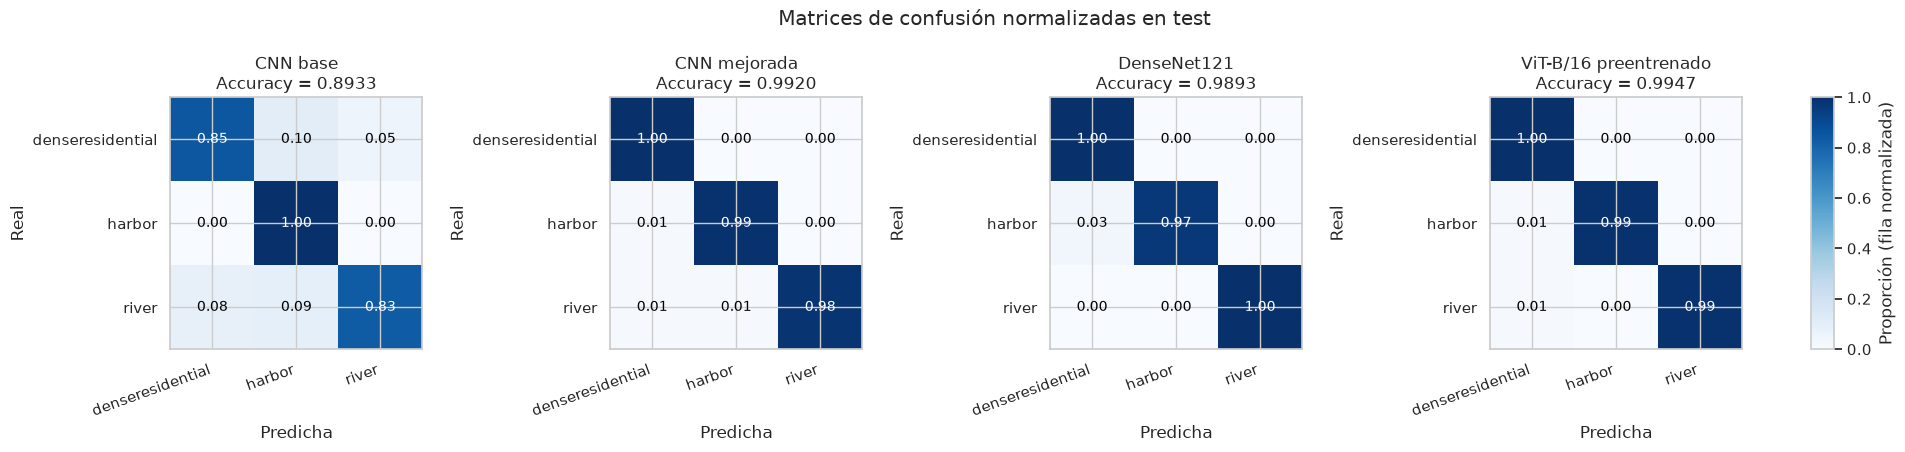

In [3]:
if not HAS_RESULTS:
    print("[aviso] Sin resultados entrenados: figura omitida.")
else:
    fig, axes = plt.subplots(1, len(results), figsize=(4.8 * len(results), 4.2))
    for ax, (_, row) in zip(np.atleast_1d(axes), results.iterrows()):
        metrics = cl.load_metrics(row["folder"])
        matrix = np.asarray(metrics["confusion_matrix"], dtype=float)
        matrix = matrix / matrix.sum(axis=1, keepdims=True)
        image = ax.imshow(matrix, cmap="Blues", vmin=0, vmax=1)
        ax.set_xticks(range(len(cl.CLASSES)), cl.CLASSES, rotation=20, ha="right")
        ax.set_yticks(range(len(cl.CLASSES)), cl.CLASSES)
        for row_index in range(len(cl.CLASSES)):
            for column_index in range(len(cl.CLASSES)):
                value = matrix[row_index, column_index]
                ax.text(
                    column_index,
                    row_index,
                    f"{value:.2f}",
                    ha="center",
                    va="center",
                    color="white" if value > 0.5 else "black",
                    fontsize=10,
                )
        ax.set_title(f"{row['model']}\nAccuracy = {row['accuracy']:.4f}")
        ax.set_xlabel("Predicha")
        ax.set_ylabel("Real")

    fig.subplots_adjust(left=0.06, right=0.90, bottom=0.22, top=0.82, wspace=0.50)
    colorbar_ax = fig.add_axes([0.925, 0.22, 0.012, 0.60])
    fig.colorbar(image, cax=colorbar_ax, label="Proporción (fila normalizada)")
    fig.suptitle("Matrices de confusión normalizadas en test", y=1.03)
    fig.savefig(comparison_dir / "matrices_confusion.png", dpi=150, bbox_inches="tight")
    plt.show()


**Qué mirar.** Las diagonales muestran qué clase se confunde. En landuse
importa especialmente si `river` se mezcla con `denseresidential` o con
`harbor`: son las confusiones que separan a los modelos preentrenados de la CNN
base.


## Figura 3: curvas de aprendizaje


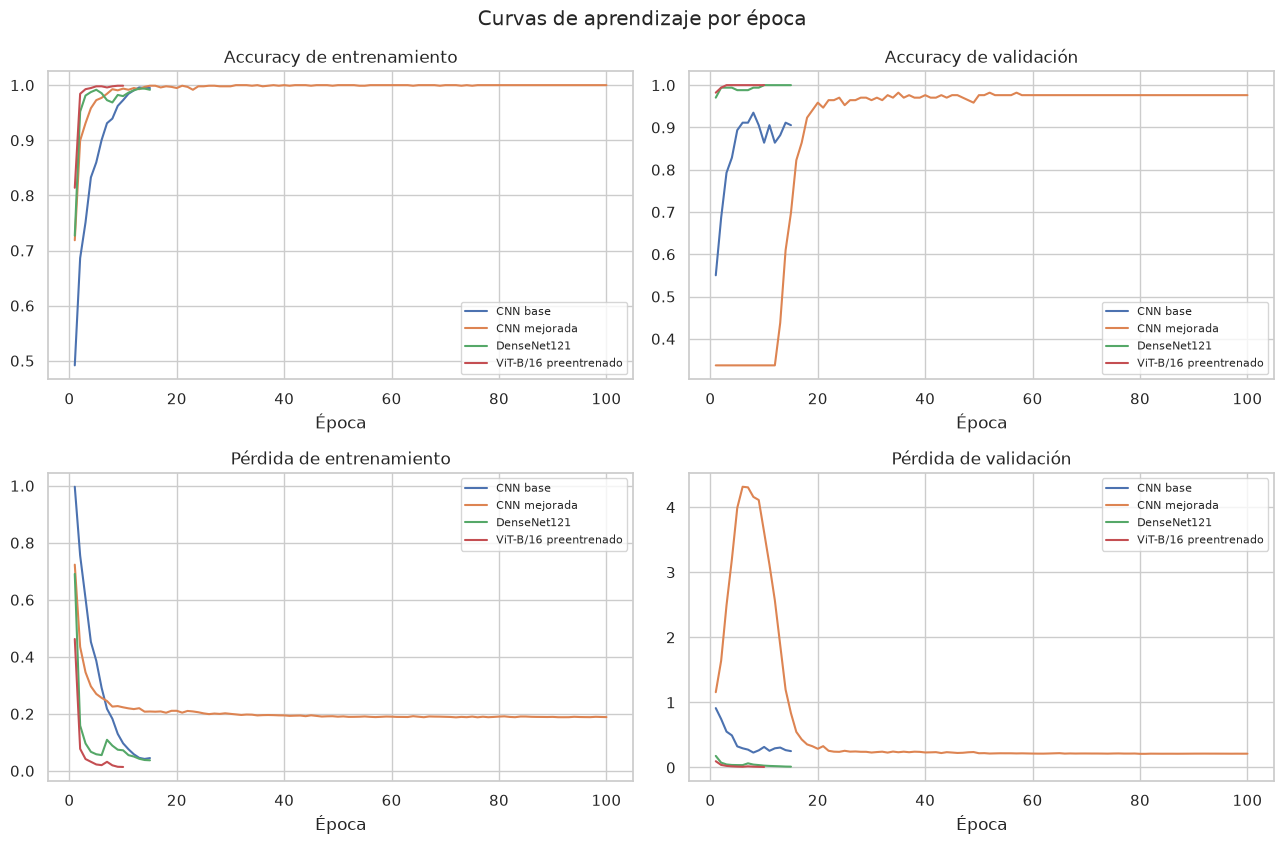

In [4]:
if not HAS_RESULTS:
    print("[aviso] Sin resultados entrenados: figura omitida.")
else:
    fig, axes = plt.subplots(2, 2, figsize=(13, 8.6))
    curves = [
        ("accuracy", "Accuracy de entrenamiento", axes[0, 0]),
        ("val_accuracy", "Accuracy de validación", axes[0, 1]),
        ("loss", "Pérdida de entrenamiento", axes[1, 0]),
        ("val_loss", "Pérdida de validación", axes[1, 1]),
    ]
    with_curves = []
    for _, row in results.iterrows():
        history = cl.load_history(row["folder"])
        if history is None:
            continue
        with_curves.append(row["model"])
        for column, _, ax in curves:
            ax.plot(history.index, history[column], label=row["model"])

    for _, title, ax in curves:
        ax.set_xlabel("Época")
        ax.set_title(title)
        ax.legend(fontsize=8)

    without_curves = [name for name in results["model"] if name not in with_curves]
    if without_curves:
        print("[nota] Sin curvas de aprendizaje: " + ", ".join(without_curves))
    fig.suptitle("Curvas de aprendizaje por época")
    fig.tight_layout()
    fig.savefig(comparison_dir / "curvas_aprendizaje.png", dpi=150, bbox_inches="tight")
    plt.show()


**Qué mirar.** La CNN base sobreajusta pronto; la CNN mejorada v2 y los
dos preentrenados mantienen la validación cerca del entrenamiento. En el ViT,
el cambio de fase (cabeza congelada → dos bloques descongelados) se ve como un
segundo tramo de la curva.


## Figura 4: F1 por clase


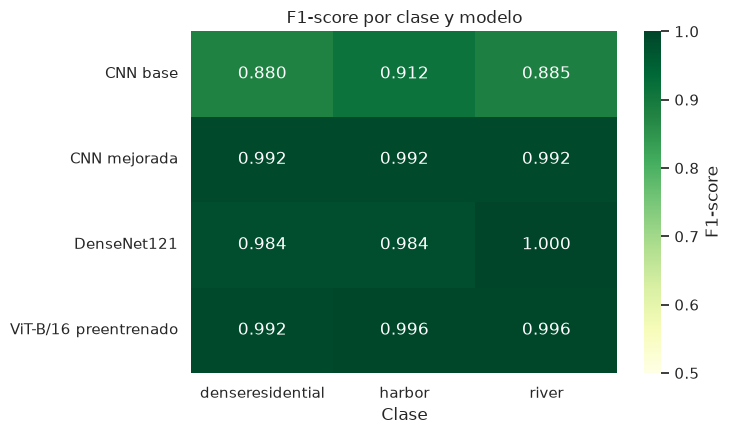

In [5]:
if not HAS_RESULTS:
    print("[aviso] Sin resultados entrenados: figura omitida.")
else:
    f1_columns = [f"f1_{class_name}" for class_name in cl.CLASSES]
    f1_matrix = results.set_index("model")[f1_columns]
    f1_matrix.columns = cl.CLASSES

    fig, ax = plt.subplots(figsize=(7.5, 4.5))
    sns.heatmap(
        f1_matrix,
        annot=True,
        fmt=".3f",
        cmap="YlGn",
        vmin=0.5,
        vmax=1,
        ax=ax,
        cbar_kws={"label": "F1-score"},
    )
    ax.set_title("F1-score por clase y modelo")
    ax.set_xlabel("Clase")
    ax.set_ylabel("")
    fig.tight_layout()
    fig.savefig(comparison_dir / "heatmap_f1_por_clase.png", dpi=150, bbox_inches="tight")
    plt.show()
    f1_matrix.round(4)


**Qué mirar.** Un accuracy alto puede esconder una clase débil. El heatmap
señala si algún modelo falla de forma sistemática en `river` o si todos
reparten los errores de manera parecida.


## Validación estadística: McNemar


In [6]:
if not HAS_RESULTS:
    print("[aviso] Sin resultados entrenados: tabla omitida.")
else:
    def model_of(folder):
        return results.loc[results["folder"] == folder, "model"].iloc[0]

    comparison_pairs = [
        ("cnn/base", "cnn/mejorada"),
        ("cnn/mejorada", "densenet"),
        ("cnn/base", "densenet"),
        ("cnn/mejorada", "vit"),
        ("densenet", "vit"),
        ("cnn/base", "vit"),
    ]
    available = set(results["folder"])
    comparison_pairs = [
        (folder_a, folder_b)
        for folder_a, folder_b in comparison_pairs
        if folder_a in available and folder_b in available
    ]

    rows = []
    for folder_a, folder_b in comparison_pairs:
        name_a, name_b = model_of(folder_a), model_of(folder_b)
        frame_a = predictions.get(name_a)
        frame_b = predictions.get(name_b)
        if frame_a is None or frame_b is None:
            p_value = np.nan
        else:
            p_value = cl.mcnemar_pvalue(
                frame_a["true_class"],
                frame_a["predicted_class"],
                frame_b["predicted_class"],
            )
        rows.append({"modelo_a": name_a, "modelo_b": name_b, "p_valor": p_value})

    mcnemar_table = pd.DataFrame(rows)
    mcnemar_table.to_csv(
        comparison_dir / "mcnemar_pvalues.csv",
        index=False,
        float_format="%.4f",
    )
    mcnemar_table.round(4)


**Qué mirar.** McNemar solo compara los casos en los que un modelo acierta
y el otro falla. Un p ≥ 0,05 indica que la diferencia observada cabe dentro del
ruido del muestreo; no prueba que los modelos sean equivalentes.


## Conclusiones


In [7]:
if not HAS_RESULTS:
    print("[aviso] Sin resultados entrenados: no hay conclusiones que generar todavía.")
else:
    by_folder = {row["folder"]: row for _, row in results.iterrows()}
    ranked = results.sort_values("accuracy", ascending=False).reset_index(drop=True)
    best = ranked.iloc[0]
    second = ranked.iloc[1]
    base = by_folder["cnn/base"]
    improved = by_folder["cnn/mejorada"]
    densenet = by_folder["densenet"]
    vit = by_folder["vit"]

    def pct(value):
        return f"{100 * value:.2f}".replace(".", ",") + " %"

    def num(value):
        return f"{int(value):,}".replace(",", ".")

    def fmt_p(value):
        if pd.isna(value):
            return "n/d"
        return f"{value:.4f}".replace(".", ",")

    def delta(value):
        sign = "+" if value >= 0 else "−"
        return sign + f"{abs(value):.2f}".replace(".", ",")

    def pvalue_of(folder_a, folder_b):
        name_a = by_folder[folder_a]["model"]
        name_b = by_folder[folder_b]["model"]
        matched = mcnemar_table[
            (
                (mcnemar_table["modelo_a"] == name_a)
                & (mcnemar_table["modelo_b"] == name_b)
            )
            | (
                (mcnemar_table["modelo_a"] == name_b)
                & (mcnemar_table["modelo_b"] == name_a)
            )
        ]
        return np.nan if matched.empty else matched["p_valor"].iloc[0]

    def verdict(value):
        if pd.isna(value):
            return "no disponible"
        return "significativa" if value < 0.05 else "dentro del ruido"

    p_vit_densenet = pvalue_of("vit", "densenet")
    p_vit_improved = pvalue_of("vit", "cnn/mejorada")
    p_densenet_improved = pvalue_of("densenet", "cnn/mejorada")
    p_base_improved = pvalue_of("cnn/base", "cnn/mejorada")
    p_base_vit = pvalue_of("cnn/base", "vit")
    gap_vit_densenet = 100 * (vit["accuracy"] - densenet["accuracy"])
    gap_vit_improved = 100 * (vit["accuracy"] - improved["accuracy"])
    gap_densenet_improved = 100 * (densenet["accuracy"] - improved["accuracy"])

    paragraphs = []
    paragraphs.append(
        "**Protocolo y continuidad.** Se usaron 1.500 imágenes de "
        "`denseresidential`, `harbor` y `river` (500 por clase), con el split "
        "común 75/15/25 y 375 imágenes de test. Se compararon cuatro modelos: "
        "CNN base, CNN mejorada con la receta v2 del reto 1, DenseNet121 "
        "preentrenada y ViT-B/16 preentrenado. La selección no es arbitraria: "
        "el reto 1 mostró que las tres CNN desde cero eran indistinguibles entre "
        "sí y que el ViT desde cero empataba con la mejor CNN, así que el reto 2 "
        "conserva un representante por familia útil y parte del ViT preentrenado."
    )
    paragraphs.append(
        f"**Resultados principales.** El mejor modelo fue {best['model']} con "
        f"accuracy {pct(best['accuracy'])} (IC 95 % {pct(best['accuracy_low'])}–"
        f"{pct(best['accuracy_high'])}) y F1 macro {pct(best['f1_macro'])}. Le "
        f"siguió {second['model']} con {pct(second['accuracy'])}. La CNN base se "
        f"quedó en {pct(base['accuracy'])} y la CNN mejorada en "
        f"{pct(improved['accuracy'])}. Los dos modelos preentrenados vuelven a "
        "quedar por delante de las CNN desde cero."
    )
    paragraphs.append(
        f"**Significancia.** ViT frente a DenseNet121: p = {fmt_p(p_vit_densenet)} "
        f"({verdict(p_vit_densenet)}), con una diferencia de "
        f"{delta(gap_vit_densenet)} puntos. ViT frente a la CNN mejorada: "
        f"p = {fmt_p(p_vit_improved)} ({verdict(p_vit_improved)}). DenseNet121 "
        f"frente a la CNN mejorada: p = {fmt_p(p_densenet_improved)} "
        f"({verdict(p_densenet_improved)}). CNN base frente a la CNN mejorada: "
        f"p = {fmt_p(p_base_improved)} ({verdict(p_base_improved)}). CNN base "
        f"frente al ViT: p = {fmt_p(p_base_vit)} ({verdict(p_base_vit)})."
    )
    paragraphs.append(
        "**Preentrenamiento y arquitectura.** La comparación reproduce la "
        "lectura del reto 1: el salto grande lo da el preentrenamiento, no la "
        "arquitectura. DenseNet121 y ViT parten de ImageNet y quedan casi "
        "empatados; la CNN mejorada, entrenada desde cero, necesita muchos más "
        "datos para acercarse. El ViT conserva la ventaja de atención global, "
        "pero no una ventaja estadística clara sobre la convolución preentrenada."
    )
    paragraphs.append(
        f"**Coste y despliegue.** La CNN base es la más barata ({num(base['parameters'])} "
        f"parámetros, {base['inference_ms_per_image']:.1f} ms/imagen), pero su "
        f"accuracy es baja. La CNN mejorada ofrece el mejor equilibrio "
        f"precisión/coste ({num(improved['parameters'])} parámetros, "
        f"{improved['inference_ms_per_image']:.1f} ms/imagen). DenseNet121 añade "
        f"precisión con {num(densenet['parameters'])} parámetros y "
        f"{densenet['inference_ms_per_image']:.1f} ms/imagen. El ViT es el más "
        f"caro: {num(vit['parameters'])} parámetros y "
        f"{vit['inference_ms_per_image']:.1f} ms/imagen en CPU."
    )
    paragraphs.append(
        f"**Elección final.** {best['model']} es la mejor opción si prima la "
        "accuracy y se dispone de hardware adecuado; DenseNet121 es la "
        "alternativa preentrenada más eficiente y la CNN mejorada la más "
        "equilibrada para CPU. La continuidad con el reto 1 se cumple: los "
        "preentrenados dominan, atención y convolución empatan, y el ViT desde "
        "cero no se repite porque no aportaba una conclusión nueva. El informe "
        "`informe-reto-2.pdf` se genera desde `resultados/`."
    )

    conclusion_text = "\n\n".join(paragraphs)
    word_count = len(conclusion_text.split())
    assert 350 <= word_count <= 400, (
        f"Las conclusiones deben tener 350-400 palabras; tienen {word_count}."
    )
    print("Conclusiones (generadas a partir de resultados/)")
    print("=" * 78)
    print(conclusion_text)
    print()
    print(f"[comprobación] {word_count} palabras")


Conclusiones (generadas a partir de resultados/)
**Protocolo y continuidad.** Se usaron 1.500 imágenes de `denseresidential`, `harbor` y `river` (500 por clase), con el split común 75/15/25 y 375 imágenes de test. Se compararon cuatro modelos: CNN base, CNN mejorada con la receta v2 del reto 1, DenseNet121 preentrenada y ViT-B/16 preentrenado. La selección no es arbitraria: el reto 1 mostró que las tres CNN desde cero eran indistinguibles entre sí y que el ViT desde cero empataba con la mejor CNN, así que el reto 2 conserva un representante por familia útil y parte del ViT preentrenado.

**Resultados principales.** El mejor modelo fue ViT-B/16 preentrenado con accuracy 99,47 % (IC 95 % 98,67 %–100,00 %) y F1 macro 99,47 %. Le siguió CNN mejorada con 99,20 %. La CNN base se quedó en 89,33 % y la CNN mejorada en 99,20 %. Los dos modelos preentrenados vuelven a quedar por delante de las CNN desde cero.

**Significancia.** ViT frente a DenseNet121: p = 0,6875 (dentro del ruido), con una di

## Notas finales y diferencias deliberadas con el reto 1

- **Cuatro modelos frente a nueve.** Es una consecuencia de los resultados del
  reto 1, no una reducción por comodidad: las variantes eliminadas no cambiaban
  la conclusión ni el orden de los modelos.
- **Dataset distinto.** 1.500 imágenes y 375 de test frente a 958 y 240 del
  reto 1. El protocolo es el mismo, pero los IC son más estrechos y los
  p-valores no son directamente comparables entre retos.
- **ViT igual al del reto 1.** Mismo preset de KerasHub
  (`vit_base_patch16_224_imagenet`), mismos dos bloques descongelados y mismo
  esquema de dos fases. El reto 2 carga las imágenes directamente a 224×224
  desde los PNG de 256×256; el reto 1 las cargaba a 128 y las redimensionaba
  dentro del modelo. Es la única diferencia de preprocesado del ViT.
- **CNN mejorada alineada.** Ahora usa la receta v2 del reto 1 y
  `Rescaling(1/255)` dentro del modelo. Antes dividía las imágenes fuera y
  aplicaba la receta v1.
- **Sin ViT desde cero ni modelos clásicos.** El reto 1 ya demostró que no
  aportan una comparación nueva; repetirlos solo añadiría coste.
- **Pesos grandes fuera de git.** `resultados/vit/model.weights.h5` (~345 MB)
  está ignorado. En un clon nuevo se reentrena con `FORCE_RETRAIN = True`.
- **Informe reproducible.** `informe_reto_2.py` genera
  `informe-reto-2.pdf` leyendo solo `resultados/`; ninguna cifra del PDF está
  escrita a mano.
